The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


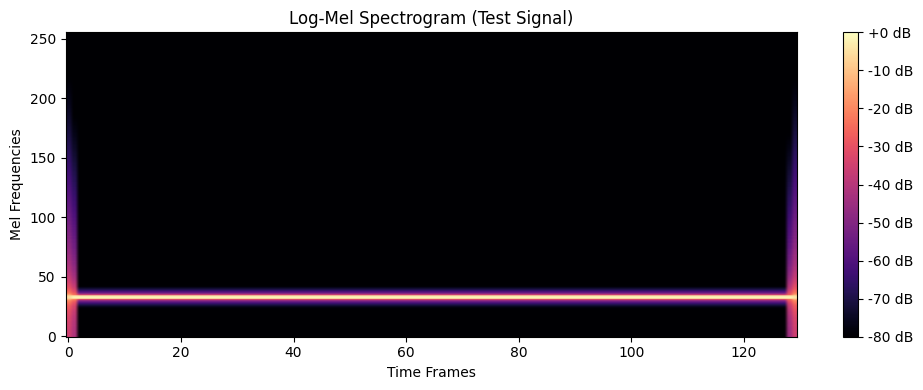

In [4]:
%load_ext autoreload
%autoreload 2
import sys
import os
import numpy as np
import matplotlib.pyplot as plt

# Add the parent folder so we can import from src
sys.path.append(os.path.abspath('..'))
from src.audio_loader import AudioPipeline

# Initialize pipeline and generate test spectrogram
pipeline = AudioPipeline(sample_rate=22050, duration=3.0)
test_signal = 0.5 * np.sin(2 * np.pi * 440 * np.linspace(0, 3.0, int(22050 * 3.0)))
spectrogram = pipeline.extract_mel_spectrogram(test_signal)

# Plot Log-Mel Spectrogram
plt.figure(figsize=(10, 4))
plt.imshow(spectrogram, aspect='auto', origin='lower', cmap='magma')
plt.colorbar(format='%+2.0f dB')
plt.title('Log-Mel Spectrogram (Test Signal)')
plt.xlabel('Time Frames')
plt.ylabel('Mel Frequencies')
plt.tight_layout()
plt.show()

Loaded 10.0s clip at 32000 Hz sampling rate.
Audio Tensor Shape: (320000,)


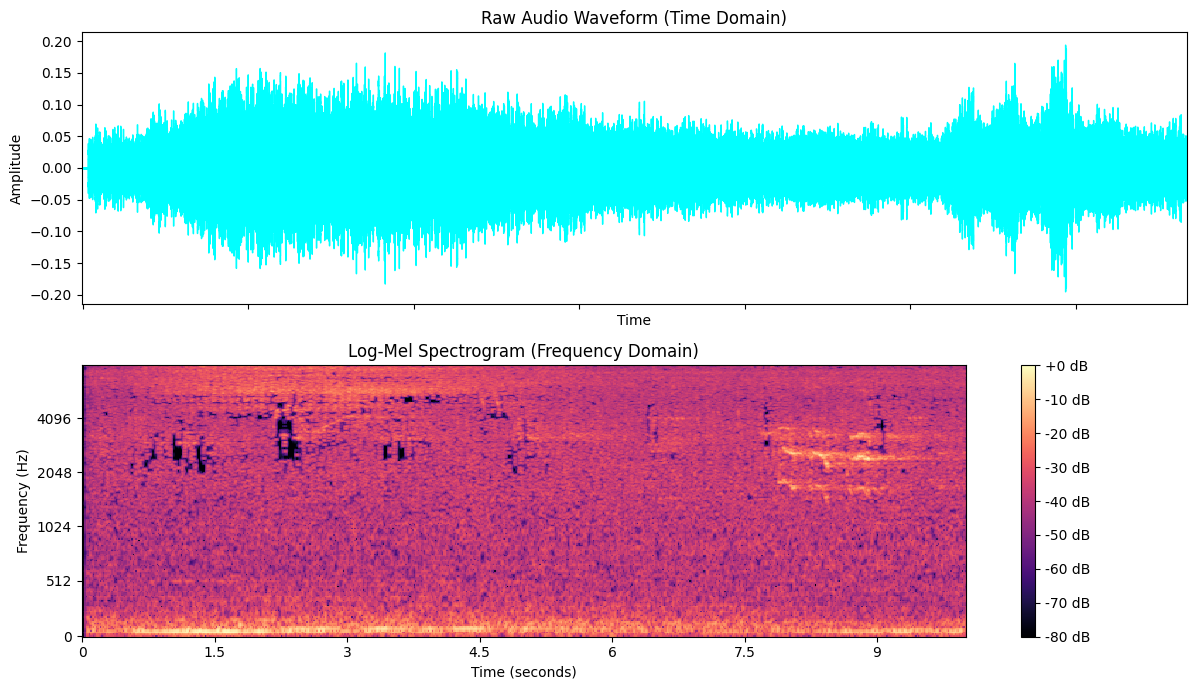

In [5]:
import sys
import os
import numpy as np
import librosa
import librosa.display
import matplotlib.pyplot as plt
from IPython.display import Audio

# 1. Define path to your newly added audio file
audio_path = '../data/freesound_community-ambient-01_junglehillswav-14614.mp3'

# 2. Load the first 10 seconds for initial exploratory analysis
duration = 10.0  # adjust duration as needed
audio, sr = librosa.load(audio_path, sr=32000, duration=duration)

print(f"Loaded {duration}s clip at {sr} Hz sampling rate.")
print(f"Audio Tensor Shape: {audio.shape}")

# 3. Compute Log-Mel Spectrogram
mel_spec = librosa.feature.melspectrogram(y=audio, sr=sr, n_mels=256, fmax=8000)
log_mel_spec = librosa.power_to_db(mel_spec, ref=np.max)

# 4. Visualise Waveform and Spectrogram side-by-side
fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

# Plot raw 1D time-domain waveform
librosa.display.waveshow(audio, sr=sr, ax=ax[0], color='cyan')
ax[0].set(title='Raw Audio Waveform (Time Domain)', ylabel='Amplitude')

# Plot 2D Log-Mel Spectrogram
img = librosa.display.specshow(log_mel_spec, sr=sr, x_axis='time', y_axis='mel', fmax=8000, ax=ax[1], cmap='magma')
fig.colorbar(img, ax=ax[1], format='%+2.0f dB')
ax[1].set(title='Log-Mel Spectrogram (Frequency Domain)', xlabel='Time (seconds)', ylabel='Frequency (Hz)')

plt.tight_layout()
plt.show()

# 5. Play audio in notebook
Audio(audio, rate=sr)

In [ ]:
%load_ext autoreload
%autoreload 2

import sys
import os
import matplotlib.pyplot as plt

sys.path.append(os.path.abspath('..'))
from src.audio_loader import AudioPipeline

# 1. Initialize pipeline
pipeline = AudioPipeline(sample_rate=32000, duration=3.0)
audio_path = '../data/freesound_community-ambient-01_junglehillswav-14614.mp3'

# 2. Slice audio into 3-second segments (50% overlap)
segments = pipeline.segment_audio(audio_path, segment_duration=3.0, overlap=0.5)

print(f"Total 3-second segments extracted: {len(segments)}")
print(f"Single segment shape: {segments[0].shape}")

# 3. Plot Mel-Spectrograms for the first 3 segments side-by-side
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i in range(3):
    spec = pipeline.extract_mel_spectrogram(segments[i], n_mels=256)
    axes[i].imshow(spec, aspect='auto', origin='lower', cmap='magma')
    axes[i].set_title(f'Segment {i+1}')
    axes[i].set_xlabel('Time Frames')
    if i == 0:
        axes[i].set_ylabel('Mel Frequencies')

plt.tight_layout()
plt.show()